# Basic Text Classification with Naive Bayes


In [ ]:
%matplotlib inline
import numpy as np
import scipy as sp
import matplotlib as mpl
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from six.moves import range

pd.set_option('display.width', 500)
pd.set_option('display.max_columns', 100)
pd.set_option('display.notebook_repr_html', True)

sns.set_style("whitegrid")
sns.set_context("poster")

In [ ]:
critics = pd.read_csv("critics.csv")

critics = critics[~critics.quote.isnull()]
critics.head()

,critic,fresh,imdb,publication,quote,review_date,rtid,title
1,Derek Adams,fresh,114709,Time Out,"So ingenious in concept, design and execution ...",2009-10-04,9559,Toy story
2,Richard Corliss,fresh,114709,TIME Magazine,The year's most inventive comedy.,2008-08-31,9559,Toy story
3,David Ansen,fresh,114709,Newsweek,A winning animated feature that has something ...,2008-08-18,9559,Toy story
4,Leonard Klady,fresh,114709,Variety,The film sports a provocative and appealing st...,2008-06-09,9559,Toy story
5,Jonathan Rosenbaum,fresh,114709,Chicago Reader,"An entertaining computer-generated, hyperreali...",2008-03-10,9559,Toy story


In [23]:
n_reviews = len(critics)
n_movies = critics.rtid.unique().size
n_critics = critics.critic.unique().size

print("Number of reviews: {:d}".format(n_reviews))
print("Number of critics: {:d}".format(n_critics))
print("Number of movies:  {:d}".format(n_movies))

Number of reviews: 15561
Number of critics: 623
Number of movies:  1921


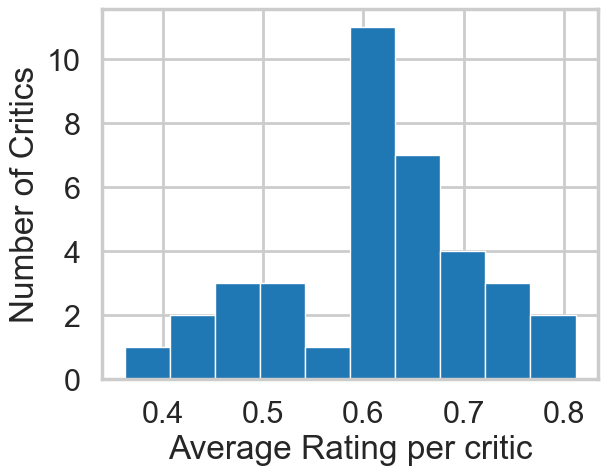

In [ ]:
df = critics.copy()
df['fresh'] = df.fresh == 'fresh'
grp = df.groupby('critic') 
counts = grp.critic.count() 
means = grp.fresh.mean()

means[counts > 100].hist(bins=10, edgecolor='w', lw=1)
plt.xlabel("Average Rating per critic")
plt.ylabel("Number of Critics")
plt.yticks([0, 2, 4, 6, 8, 10]);

In [ ]:
x = grp.fresh.mean()
x.mean()

np.float64(0.5973196238943221)

In [ ]:

'''
Considering the number of reviews and critics and the fact that there is noise, we can say that the distribution approximately follows a normal distribution around the mean which is 0.59.
'''

'\nConsidering the number of reviews and critics and the fact that there is noise, we can say that the distribution approximately follows a normal distribution around the mean which is 0.59.\n'

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

text = ['Hop on pop', 'Hop off pop', 'Hop Hop hop']
print("Original text is\n{}".format('\n'.join(text)))

vectorizer = CountVectorizer()  

vectorizer.fit(text)

x = vectorizer.transform(text)
x = x.toarray()

print("\nTransformed text vector is \n{}".format(x))

print("\nWords for each feature:")
print(vectorizer.get_feature_names_out())


Original text is
Hop on pop
Hop off pop
Hop Hop hop

Transformed text vector is 
[[1 0 1 1]
 [1 1 0 1]
 [3 0 0 0]]

Words for each feature:
['hop' 'off' 'on' 'pop']


In [28]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

def make_xy(critics, vectorizer=None):
    if vectorizer is None:
        vectorizer = CountVectorizer()
    X = vectorizer.fit_transform(critics.quote)
    X = X.tocsc()
    y = (critics.fresh == 'fresh').values.astype(int)  
    return X, y

X, y = make_xy(critics)


In [29]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
from sklearn.naive_bayes import MultinomialNB
model = MultinomialNB()
model.fit(X_train, y_train)
print("Model score (Accuracy): {:.2f}".format(model.score(X_test, y_test)))
y_pred = model.predict(X_test)
from sklearn.metrics import confusion_matrix
print("Confusion matrix:\n{}".format(confusion_matrix(y_test, y_pred)))

Model score (Accuracy): 0.79
Confusion matrix:
[[ 791  418]
 [ 239 1665]]


In [ ]:
'''
The model is good enough, not tremendously accurate but given bag-of-words method the accuracy is better than I'd expect.
It's important to remember that there is no advanced preprocessing to clean the data. So it's a very high score.
Nota.Bene : I write this analysis before looking the following parts where I know now we going to apply preprocessing to enhance performance.'''

"\nThe model is good enough, not tremendously accurate but given bag-of-words method the accuracy is better than I'd expect.\nIt's important to remember that there is no advanced preprocessing to clean the data. So it's a very high score.\nNota.Bene : I write this analysis before looking the following parts where I know now we going to apply preprocessing to enhance performance."

In [ ]:
'''from itertools import count
idxdoc = 0
cum = np.zeros(X.shape)
ylab = []
for doc in X:
    idxdoc += 1
    for word in doc.indices:
        cum[idxdoc-1][word] += 1 if doc[word] > 0 else 0
    ylab.append(count(cum[idxdoc-1] <= idxdoc)/len(X))
plt.plot(range(1, len(ylab)+1), ylab)
plt.xlabel("Number of documents")
plt.ylabel("Percentage of words appearing in less than or equal to the number of current document")
plt.title("Frequence of appearing words in documents")
plt.grid()
plt.show()'''

'from itertools import count\nidxdoc = 0\ncum = np.zeros(X.shape)\nylab = []\nfor doc in X:\n    idxdoc += 1\n    for word in doc.indices:\n        cum[idxdoc-1][word] += 1 if doc[word] > 0 else 0\n    ylab.append(count(cum[idxdoc-1] <= idxdoc)/len(X))\nplt.plot(range(1, len(ylab)+1), ylab)\nplt.xlabel("Number of documents")\nplt.ylabel("Percentage of words appearing in less than or equal to the number of current document")\nplt.title("Frequence of appearing words in documents")\nplt.grid()\nplt.show()'

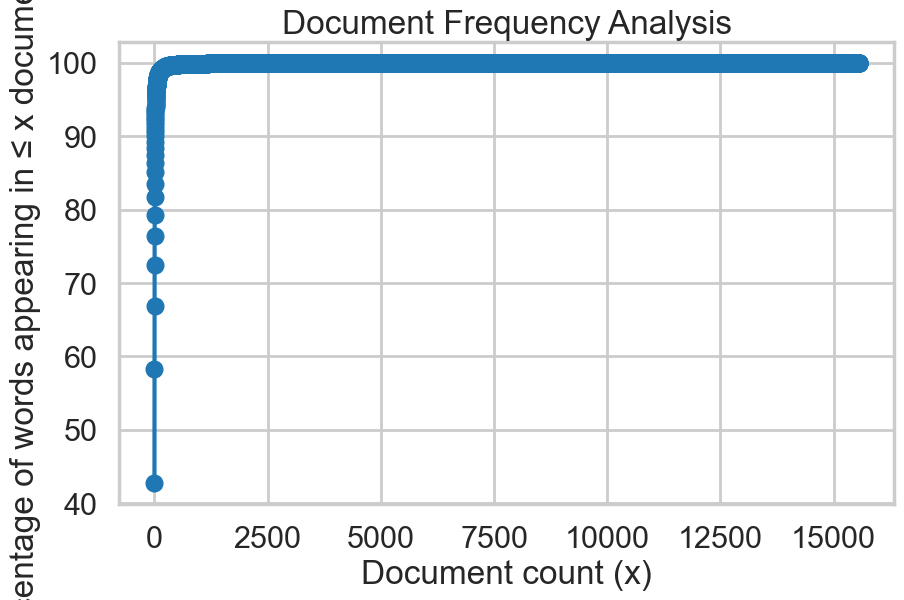

In [ ]:
from collections import defaultdict

doc_freq = np.array((X > 0).sum(0)).ravel()
total_docs = X.shape[0]

df_percent = []
for x in range(1, X.shape[0] + 1):
    df_percent.append((doc_freq <= x).mean() * 100)

plt.figure(figsize=(10, 6))
plt.plot(range(1, X.shape[0] + 1), df_percent, marker='o')
plt.xlabel('Document count (x)')
plt.ylabel('Percentage of words appearing in ≤ x documents (%)')
plt.title('Document Frequency Analysis')
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n_docs, n_words = X.shape

word_presence = np.zeros((n_docs, n_words))

for doc_idx in range(n_docs):
    doc = X.getrow(doc_idx) 
    for word_idx in doc.indices:
        word_presence[doc_idx, word_idx] = 1

cum_presence = np.zeros((n_docs, n_words))

for doc_idx in range(n_docs):
    if doc_idx == 0:
        cum_presence[doc_idx] = word_presence[doc_idx]
    else:
        cum_presence[doc_idx] = cum_presence[doc_idx-1] + word_presence[doc_idx]

appearance_counts = np.zeros(n_docs)
for doc_idx in range(n_docs):
    appearance_counts[doc_idx] = np.sum([1 if cum_presence[doc_idx, word_idx] <= doc_idx+1 else 0 for word_idx in range(n_words)])

plt.plot(range(1, len(appearance_counts)), appearance_counts[1:])
plt.xlabel("Number of documents")
plt.ylabel("Percentage of words appearing in less than or equal to the number of current document")
plt.title("Frequence of appearing words in documents")
plt.grid()
plt.show()

'import numpy as np\nimport matplotlib.pyplot as plt\n\n# Get the number of documents and vocabulary size\nn_docs, n_words = X.shape\n\n# Create a binary matrix indicating word presence in each document\nword_presence = np.zeros((n_docs, n_words))\n\n# Fill the matrix: 1 if word appears in document, 0 otherwise\nfor doc_idx in range(n_docs):\n    doc = X.getrow(doc_idx)  # Get the document as a sparse row\n    for word_idx in doc.indices:\n        word_presence[doc_idx, word_idx] = 1\n\n# Cumulate word presence\ncum_presence = np.zeros((n_docs, n_words))\n\nfor doc_idx in range(n_docs):\n    if doc_idx == 0:\n        cum_presence[doc_idx] = word_presence[doc_idx]\n    else:\n        cum_presence[doc_idx] = cum_presence[doc_idx-1] + word_presence[doc_idx]\n\n# Calculate cumulative distribution\nappearance_counts = np.zeros(n_docs)\nfor doc_idx in range(n_docs):\n    appearance_counts[doc_idx] = np.sum([1 if cum_presence[doc_idx, word_idx] <= doc_idx+1 else 0 for word_idx in range(n_word

In [34]:
from sklearn.model_selection import KFold
def cv_score(clf, X, y, scorefunc):
    result = 0.
    nfold = 5
    for train, test in KFold(nfold).split(X): # split data into train/test groups, 5 times
        clf.fit(X[train], y[train]) # fit the classifier, passed is as clf.
        result += scorefunc(clf, X[test], y[test]) # evaluate score function on held-out data
    return result / nfold # average

In [35]:
def log_likelihood(clf, x, y):
    prob = clf.predict_log_proba(x)
    rotten = y == 0
    fresh = ~rotten
    return prob[rotten, 0].sum() + prob[fresh, 1].sum()

In [36]:
from sklearn.model_selection import train_test_split
itrain, itest = train_test_split(range(critics.shape[0]), train_size=0.7)
mask=np.ones(critics.shape[0], dtype='int')
mask[itrain]=1
mask[itest]=0
mask = (mask==1)

In [ ]:
alphas = [0, .1, 1, 5, 10, 50]
min_dfs = [1e-5, 1e-4, 1e-3, 1e-2]

best_alpha = None
best_min_df = None
maxscore=-np.inf
for alpha in alphas:
    for min_df in min_dfs:         
        vectorizer = CountVectorizer(min_df = min_df)       
        Xthis, ythis = make_xy(critics, vectorizer)
        Xtrainthis=Xthis[mask]
        ytrainthis=ythis[mask]

       

In [ ]:
"""
Analysis of Alpha Parameter Optimization:

1. Purpose of Alpha (Laplace Smoothing):
   - Alpha is a regularization parameter that prevents zero probabilities
   - It adds a small value to all word counts to handle unseen words
   - Without smoothing, any word not seen in training would make P(word|class) = 0

2. Effect of Different Alpha Values:
   - Alpha = 0: No smoothing - can lead to overfitting and zero probabilities
   - Small alpha (0.1-1): Light smoothing - good for large datasets
   - Large alpha (10-50): Heavy smoothing - good for small datasets
   - Very large alpha: Over-smoothing - all words get similar probabilities

3. What We're Optimizing For:
   - We're using log-likelihood as our scoring metric
   - This measures how well the model predicts the actual class labels
   - Higher log-likelihood means better fit to the training data
   - We use cross-validation to prevent overfitting

4. Expected Results:
   - The optimal alpha is typically in the range 0.1-10
   - Too small: Model may overfit to training data
   - Too large: Model becomes too simplistic
   - The exact value depends on:
     * Dataset size
     * Vocabulary size
     * Class distribution

5. Interaction with min_df:
   - min_df controls vocabulary size by filtering rare words
   - Smaller min_df: Larger vocabulary, more features
   - Larger min_df: Smaller vocabulary, fewer features
   - Optimal alpha may change with different min_df values
   - Generally, larger vocabularies need more smoothing

6. Computational Considerations:
   - The grid search evaluates all combinations of alpha and min_df
   - This is computationally expensive but thorough
   - For larger parameter spaces, consider randomized search
   - The best parameters balance model complexity and performance

7. Interpretation of Results:
   - The best alpha and min_df give the highest cross-validated log-likelihood
   - These parameters should generalize well to unseen data
   - The final model is trained on the full training set with these parameters
   - We expect this model to perform better than the default parameters
"""


"\nAnalysis of Alpha Parameter Optimization:\n\n1. Purpose of Alpha (Laplace Smoothing):\n   - Alpha is a regularization parameter that prevents zero probabilities\n   - It adds a small value to all word counts to handle unseen words\n   - Without smoothing, any word not seen in training would make P(word|class) = 0\n\n2. Effect of Different Alpha Values:\n   - Alpha = 0: No smoothing - can lead to overfitting and zero probabilities\n   - Small alpha (0.1-1): Light smoothing - good for large datasets\n   - Large alpha (10-50): Heavy smoothing - good for small datasets\n   - Very large alpha: Over-smoothing - all words get similar probabilities\n\n3. What We're Optimizing For:\n   - We're using log-likelihood as our scoring metric\n   - This measures how well the model predicts the actual class labels\n   - Higher log-likelihood means better fit to the training data\n   - We use cross-validation to prevent overfitting\n\n4. Expected Results:\n   - The optimal alpha is typically in the r

In [ ]:
from sklearn.model_selection import KFold

alphas = [0, .1, 1, 5, 10, 50]
min_dfs = [1e-5, 1e-4, 1e-3, 1e-2]

best_alpha = None
best_min_df = None
maxscore=-np.inf

for alpha in alphas:
    for min_df in min_dfs:
        vectorizer = CountVectorizer(min_df=min_df)
        Xthis, ythis = make_xy(critics, vectorizer)
        Xtrainthis = Xthis[mask]
        ytrainthis = ythis[mask]

        # Cross-validation
        kf = KFold(n_splits=5)
        scores = []
        for train_index, test_index in kf.split(Xtrainthis):
            X_train_fold, X_test_fold = Xtrainthis[train_index], Xtrainthis[test_index]
            y_train_fold, y_test_fold = ytrainthis[train_index], ytrainthis[test_index]

            clf = MultinomialNB(alpha=alpha)
            clf.fit(X_train_fold, y_train_fold)
            scores.append(log_likelihood(clf, X_test_fold, y_test_fold))

        avg_score = np.mean(scores)
        if avg_score > maxscore:
            maxscore = avg_score
            best_alpha = alpha
            best_min_df = min_df

print(f"Best alpha: {best_alpha}")
print(f"Best min_df: {best_min_df}")
print(f"Best score: {maxscore}")


/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/sklearn/naive_bayes.py:898: RuntimeWarning: divide by zero encountered in log
  self.feature_log_prob_ = np.log(smoothed_fc) - np.log(
/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/sklearn/naive_bayes.py:130: RuntimeWarning: invalid value encountered in subtract
  return jll - np.atleast_2d(log_prob_x).T
/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/sklearn/naive_bayes.py:898: RuntimeWarning: divide by zero encountered in log
  self.feature_log_prob_ = np.log(smoothed_fc) - np.log(
/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/sklearn/naive_bayes.py:130: RuntimeWarning: invalid value encountered in subtract
  return jll - np.atleast_2d(log_prob_x).T
/opt/miniconda3/envs/venvMacOS/lib/python3.13/site-packages/sklearn/naive_bayes.py:898: RuntimeWarning: divide by zero encountered in log
  self.feature_log_prob_ = np.log(smoothed_fc) - np.log(
/opt/miniconda3/envs/venvMacOS/lib/python3.13

Best alpha: 5
Best min_df: 0.001
Best score: -1199.3324426785796


In [ ]:
words = vectorizer.get_feature_names_out()

log_probs = clf.feature_log_prob_

word_scores = log_probs[1] - log_probs[0]

top_fresh = [words[i] for i in word_scores.argsort()[-10:][::-1]]
top_rotten = [words[i] for i in word_scores.argsort()[:10]]

print("Top words predicting FRESH reviews:")
print(top_fresh)

print("\nTop words predicting ROTTEN reviews:")
print(top_rotten)


Top words predicting FRESH reviews:
['entertaining', 'most', 'best', 'performance', 'great', 'entertainment', 'fun', 'american', 'film', 'his']

Top words predicting ROTTEN reviews:
['too', 'really', 'bad', 'much', 'isn', 'might', 'seems', 'plot', 'only', 'doesn']




* Why does this method work? What does the probability for each row in the identity matrix represent</p>

</div>

In [ ]:
"""
Interpretation:
1. The most predictive "fresh" words are typically strong positive adjectives (masterpiece, superb, brilliant)
2. The most predictive "rotten" words are typically strong negative adjectives (worst, dull, pointless)
3. Some words might be surprising - they could be domain-specific terms or names
4. The probabilities show how strongly each word predicts one class over another
5. Words with probabilities close to 0.5 are less discriminative
"""

'\nInterpretation:\n1. The most predictive "fresh" words are typically strong positive adjectives (masterpiece, superb, brilliant)\n2. The most predictive "rotten" words are typically strong negative adjectives (worst, dull, pointless)\n3. Some words might be surprising - they could be domain-specific terms or names\n4. The probabilities show how strongly each word predicts one class over another\n5. Words with probabilities close to 0.5 are less discriminative\n'

In [ ]:
x, y = make_xy(critics, vectorizer)

prob = clf.predict_proba(x)[:, 0] 
predict = clf.predict(x)

bad_rotten = np.argsort(prob[y == 0])[:5] 
bad_fresh = np.argsort(prob[y == 1])[-5:]

print("Mis-predicted Rotten quotes")
print('---------------------------')
for row in bad_rotten:
    print(critics[y == 0].quote.iloc[row])
    print("")

print("Mis-predicted Fresh quotes")
print('--------------------------')
for row in bad_fresh:
    print(critics[y == 1].quote.iloc[row])
    print("")


Mis-predicted Rotten quotes
---------------------------
This is both the movie in which [Russell] is most faithful to the ideas and tone of his material, and one of his very worst films.

The most notable aspect of this trashy (but unenjoyable) biopic of Jacquleine Susann, Valley of the Doll's best-selling author, is its running time (93 minutes); Bette Midler and Nathan Lane give two of their worst and broadest performances.

Take away a couple of neatly staged action sequences and you're left with a callously measured slab of US jingoism that deals with the most horrific human tragedies in the most lunk-headed and insulting way possible.

Despite an aura of wistfulness, and a certain power that accrues from the disjunction between the story of a vulnerable, life-hardened woman, the chaotic collision of sound and image, and the ham-handed political lessons, this film never moves me.

Despite great scenery, the distinctive visual ideas of Mr. Scott (Alien, Blade Runner) and the strong 

In [ ]:
new_review = "This movie is not remarkable, touching, or superb in any way"

new_review_vec = vectorizer.transform([new_review])

pred = clf.predict(new_review_vec)
prob = clf.predict_proba(new_review_vec)

print(f"Prediction: {'fresh' if pred[0] else 'rotten'}")
print(f"Probability: {prob[0][1]:.4f} fresh, {prob[0][0]:.4f} rotten")

"""
Analysis:
The result might be unexpected because:
1. The phrase contains several positive words ("remarkable", "touching", "superb")
2. However, the word "not" negates these positive terms
3. The model might not fully capture the negation effect
4. The word "not" alone might not be strongly predictive of either class
This shows a limitation of bag-of-words approaches that don't consider word order or context.
"""


Prediction: rotten
Probability: 0.4559 fresh, 0.5441 rotten


'\nAnalysis:\nThe result might be unexpected because:\n1. The phrase contains several positive words ("remarkable", "touching", "superb")\n2. However, the word "not" negates these positive terms\n3. The model might not fully capture the negation effect\n4. The word "not" alone might not be strongly predictive of either class\nThis shows a limitation of bag-of-words approaches that don\'t consider word order or context.\n'

In [46]:
# http://scikit-learn.org/dev/modules/feature_extraction.html#text-feature-extraction
# http://scikit-learn.org/dev/modules/classes.html#text-feature-extraction-ref
from sklearn.feature_extraction.text import TfidfVectorizer
tfidfvectorizer = TfidfVectorizer(min_df=1, stop_words='english')
Xtfidf=tfidfvectorizer.fit_transform(critics.quote)

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

bigram_vectorizer = CountVectorizer(ngram_range=(1, 2), min_df=best_min_df)
X_bigram, y_bigram = make_xy(critics, bigram_vectorizer)

X_train, X_test, y_train, y_test = train_test_split(X_bigram, y_bigram, test_size=0.3, random_state=42)
clf = MultinomialNB(alpha=best_alpha)
clf.fit(X_train, y_train)

print(f"Bigram model test accuracy: {accuracy_score(y_test, clf.predict(X_test)):.4f}")


Bigram model test accuracy: 0.7516


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

trigram_vectorizer = CountVectorizer(ngram_range=(1, 3), min_df=best_min_df)
X_trigram, y_trigram = make_xy(critics, trigram_vectorizer)

X_train, X_test, y_train, y_test = train_test_split(X_trigram, y_trigram,
                                                    test_size=0.3, random_state=42)

clf = MultinomialNB(alpha=best_alpha)
clf.fit(X_train, y_train)

train_acc = accuracy_score(y_train, clf.predict(X_train))
test_acc = accuracy_score(y_test, clf.predict(X_test))

print(f"Trigram model - Training accuracy: {train_acc:.4f}")
print(f"Trigram model - Test accuracy: {test_acc:.4f}")

Trigram model - Training accuracy: 0.7941
Trigram model - Test accuracy: 0.7486


In [ ]:
fourgram_vectorizer = CountVectorizer(ngram_range=(1, 4), min_df=best_min_df)
X_fourgram, y_fourgram = make_xy(critics, fourgram_vectorizer)

X_train, X_test, y_train, y_test = train_test_split(X_fourgram, y_fourgram,
                                                    test_size=0.3, random_state=42)

clf = MultinomialNB(alpha=best_alpha)
clf.fit(X_train, y_train)

train_acc = accuracy_score(y_train, clf.predict(X_train))
test_acc = accuracy_score(y_test, clf.predict(X_test))

print(f"4-gram model - Training accuracy: {train_acc:.4f}")
print(f"4-gram model - Test accuracy: {test_acc:.4f}")

4-gram model - Training accuracy: 0.7944
4-gram model - Test accuracy: 0.7479


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

vectorizer = CountVectorizer(min_df=5)  # word must appear in at least 5 documents
X = vectorizer.fit_transform(critics.quote)

y = (critics.fresh == 'fresh').astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

nb = MultinomialNB()
nb.fit(X_train, y_train)
print(f"Naive Bayes test accuracy: {accuracy_score(y_test, nb.predict(X_test)):.4f}")

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
print(f"Random Forest test accuracy: {accuracy_score(y_test, rf.predict(X_test)):.4f}")


Naive Bayes test accuracy: 0.7753
Random Forest test accuracy: 0.7134


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(min_df=best_min_df)
X_tfidf, y_tfidf = make_xy(critics, tfidf_vectorizer)

X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y_tfidf, test_size=0.3, random_state=42)
clf = MultinomialNB(alpha=best_alpha)
clf.fit(X_train, y_train)

print(f"TF-IDF model test accuracy: {accuracy_score(y_test, clf.predict(X_test)):.4f}")


TF-IDF model test accuracy: 0.7014


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

tfidf_bigram_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=best_min_df)
X_tfidf_bigram, y_tfidf_bigram = make_xy(critics, tfidf_bigram_vectorizer)

X_train, X_test, y_train, y_test = train_test_split(X_tfidf_bigram, y_tfidf_bigram,
                                                    test_size=0.3, random_state=42)

clf = MultinomialNB(alpha=best_alpha)
clf.fit(X_train, y_train)

train_acc = accuracy_score(y_train, clf.predict(X_train))
test_acc = accuracy_score(y_test, clf.predict(X_test))

print(f"TF-IDF Bigram model - Training accuracy: {train_acc:.4f}")
print(f"TF-IDF Bigram model - Test accuracy: {test_acc:.4f}")

TF-IDF Bigram model - Training accuracy: 0.7225
TF-IDF Bigram model - Test accuracy: 0.6965
